# 08 · Price context (Prompt 13)

**Descriptive only.** Prices move with gas prices, weather, transmission and policy as well as demand; nothing here is a causal
estimate of what data centers did to prices. Built by `python -m glg.ingest.iso_markets` and `python -m glg.ingest.eia861`.
Sources and licences: NOTICE.md.

In [1]:
import polars as pl, matplotlib.pyplot as plt, numpy as np
from datetime import date
from glg.config import FIGURES_DIR
from glg.ingest import iso_markets as im, eia861
pl.Config(tbl_rows=40, tbl_cols=16, tbl_width_chars=230)
cap = pl.read_parquet(im.CAPACITY_PATH); w = pl.read_parquet(im.WHOLESALE_PATH); retail = pl.read_parquet(eia861.RETAIL_PATH)

## PJM capacity auction (Base Residual Auction) clearing prices, $/MW-day UCAP

In [2]:
cap.drop('source')

delivery_year,rto_price,dom_price,dom_in_rpm,rto_uncapped,dom_uncapped,cap,floor,shortfall_mw_ucap,start_year
str,f64,f64,bool,f64,f64,f64,f64,f64,i32
"""2018/19""",164.77,null,false,null,null,null,null,null,2018
"""2019/20""",100.0,null,false,null,null,null,null,null,2019
"""2020/21""",76.53,null,false,null,null,null,null,null,2020
"""2021/22""",140.0,null,false,null,null,null,null,null,2021
"""2022/23""",50.0,null,false,null,null,null,null,null,2022
"""2023/24""",34.13,null,false,null,null,null,null,null,2023
"""2024/25""",28.92,null,false,null,null,null,null,null,2024
"""2025/26""",269.92,444.26,true,null,null,null,null,null,2025
"""2026/27""",329.17,329.17,true,388.57,null,329.17,175.0,null,2026


## Annual wholesale energy prices, $/MWh

In [3]:
locs = ['DOM', 'PJM', 'BGE', 'HB_HUBAVG', 'HB_NORTH', 'HB_WEST', 'Palo Verde', 'Mid-C', 'PJM West']
w.filter(pl.col('location').is_in(locs)).pivot('year', index=['source', 'location'], values='price_usd_mwh', sort_columns=True).with_columns(
    pl.col(pl.Float64).round(1))

source,location,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""PJM IMM State of the Market""","""BGE""",39.3,33.7,44.0,30.8,25.8,45.8,95.4,38.8,44.9,63.1
"""PJM IMM State of the Market""","""DOM""",32.2,32.2,43.8,27.7,23.0,44.7,99.5,37.5,39.1,65.6
"""PJM IMM State of the Market""","""PJM""",29.3,30.4,38.2,27.3,21.8,39.8,80.1,31.1,33.7,50.7
"""ERCOT (via gridstatus)""","""HB_WEST""",20.5,22.3,27.9,34.6,19.4,145.7,57.5,49.4,27.4,32.9
"""ERCOT (via gridstatus)""","""HB_HUBAVG""",21.6,24.9,29.7,35.8,21.2,148.2,62.3,48.4,26.8,32.5
"""ERCOT (via gridstatus)""","""HB_NORTH""",21.1,23.3,30.0,35.9,21.5,149.6,62.2,48.3,25.9,32.0
"""EIA Wholesale Electricity Mark…","""Mid-C""",23.0,26.0,37.4,38.3,24.8,58.8,92.8,88.6,61.8,46.2
"""EIA Wholesale Electricity Mark…","""PJM West""",34.5,35.0,41.5,31.6,24.9,45.7,86.6,39.3,42.4,60.2
"""EIA Wholesale Electricity Mark…","""Palo Verde""",25.5,32.8,42.4,32.5,47.6,61.6,98.1,73.5,39.3,35.2


In [4]:
dom = w.filter(pl.col('location').is_in(['DOM', 'PJM'])).pivot('location', index='year', values='price_usd_mwh').sort('year')
dom.with_columns((pl.col('DOM') - pl.col('PJM')).alias('DOM premium $/MWh'), (100 * (pl.col('DOM') / pl.col('PJM') - 1)).alias('DOM premium %')).with_columns(
    pl.col(pl.Float64).round(1))

year,DOM,PJM,DOM premium $/MWh,DOM premium %
i32,f64,f64,f64,f64
2016,32.2,29.3,2.9,9.9
2017,32.2,30.4,1.8,6.0
2018,43.8,38.2,5.5,14.4
2019,27.7,27.3,0.4,1.4
2020,23.0,21.8,1.3,5.9
2021,44.7,39.8,4.9,12.3
2022,99.5,80.1,19.4,24.2
2023,37.5,31.1,6.4,20.7
2024,39.1,33.7,5.3,15.8


## Chart 6: PJM capacity prices

Step chart of the RTO clearing price by delivery year (June–May). DOM is shown from 2025/26, the first auction its load joined
(before that Dominion self-supplied capacity under the Fixed Resource Requirement alternative).

2026-11-08 17:50:46,364 INFO chart6_pjm_capacity (light): chart6_pjm_capacity.png, chart6_pjm_capacity.svg


2026-11-08 17:50:46,522 INFO chart6_pjm_capacity (dark): chart6_pjm_capacity_dark.png, chart6_pjm_capacity_dark.svg


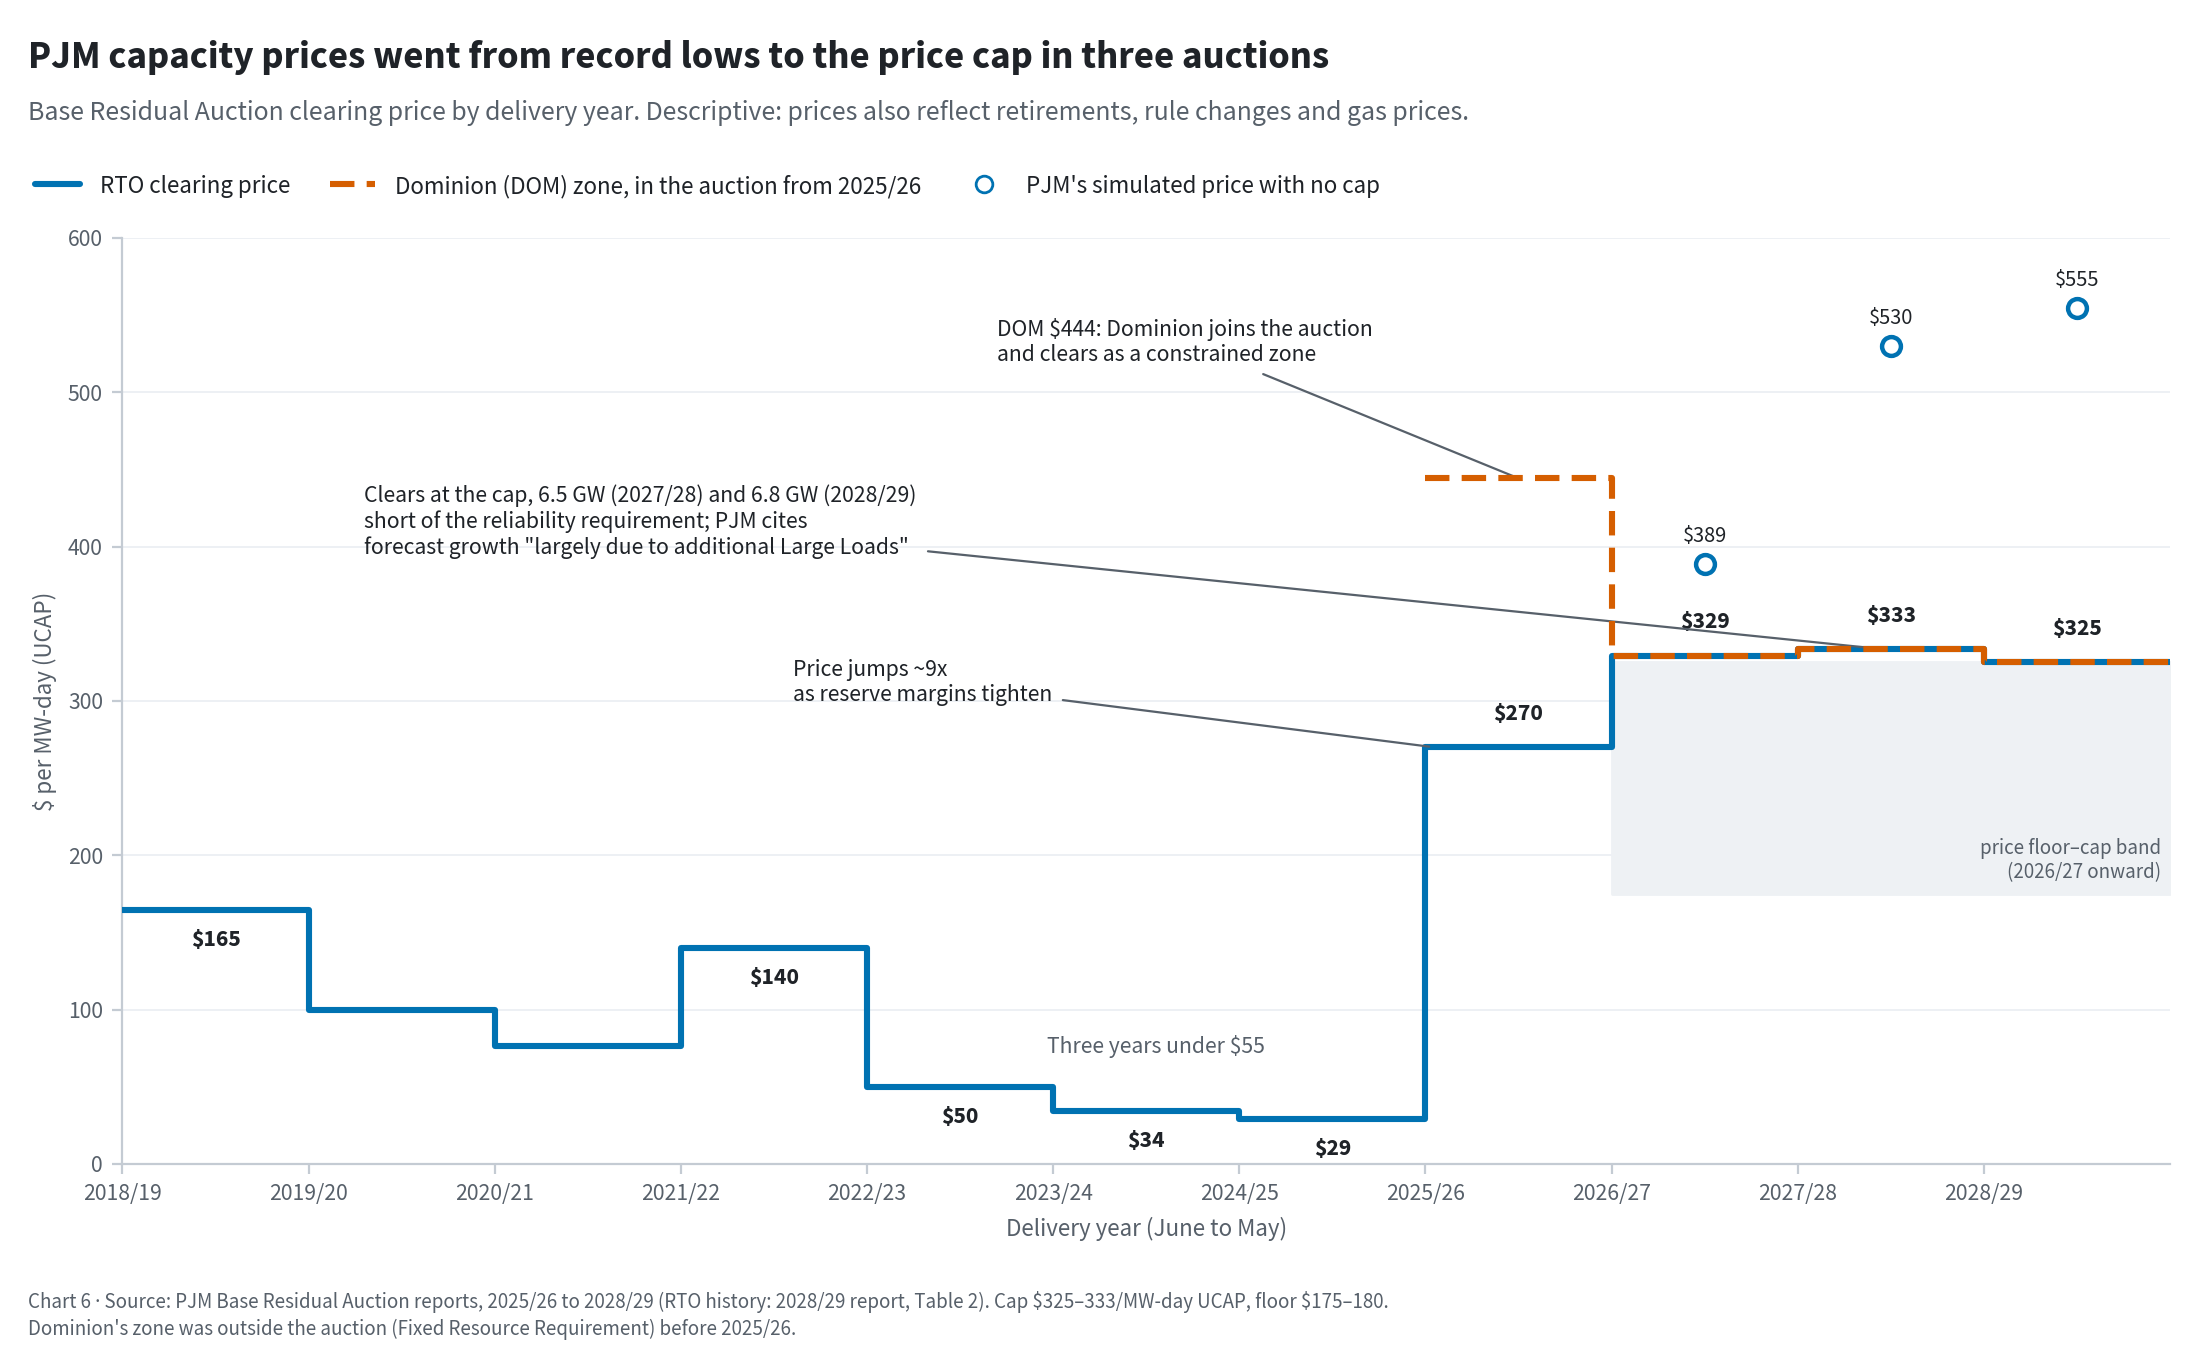

In [5]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['chart6_pjm_capacity'])
Image(filename=str(F.FIGURES_DIR / 'chart6_pjm_capacity.png'), width=900)

## Retail prices: Virginia, Texas, Georgia and Arizona vs the U.S.

Average revenue per kWh by sector, in constant 2025 dollars (CPI-U). The last point is the 12 months to the latest month.

2026-11-08 17:50:46,754 INFO retail_prices (light): retail_prices.png, retail_prices.svg


2026-11-08 17:50:46,979 INFO retail_prices (dark): retail_prices_dark.png, retail_prices_dark.svg


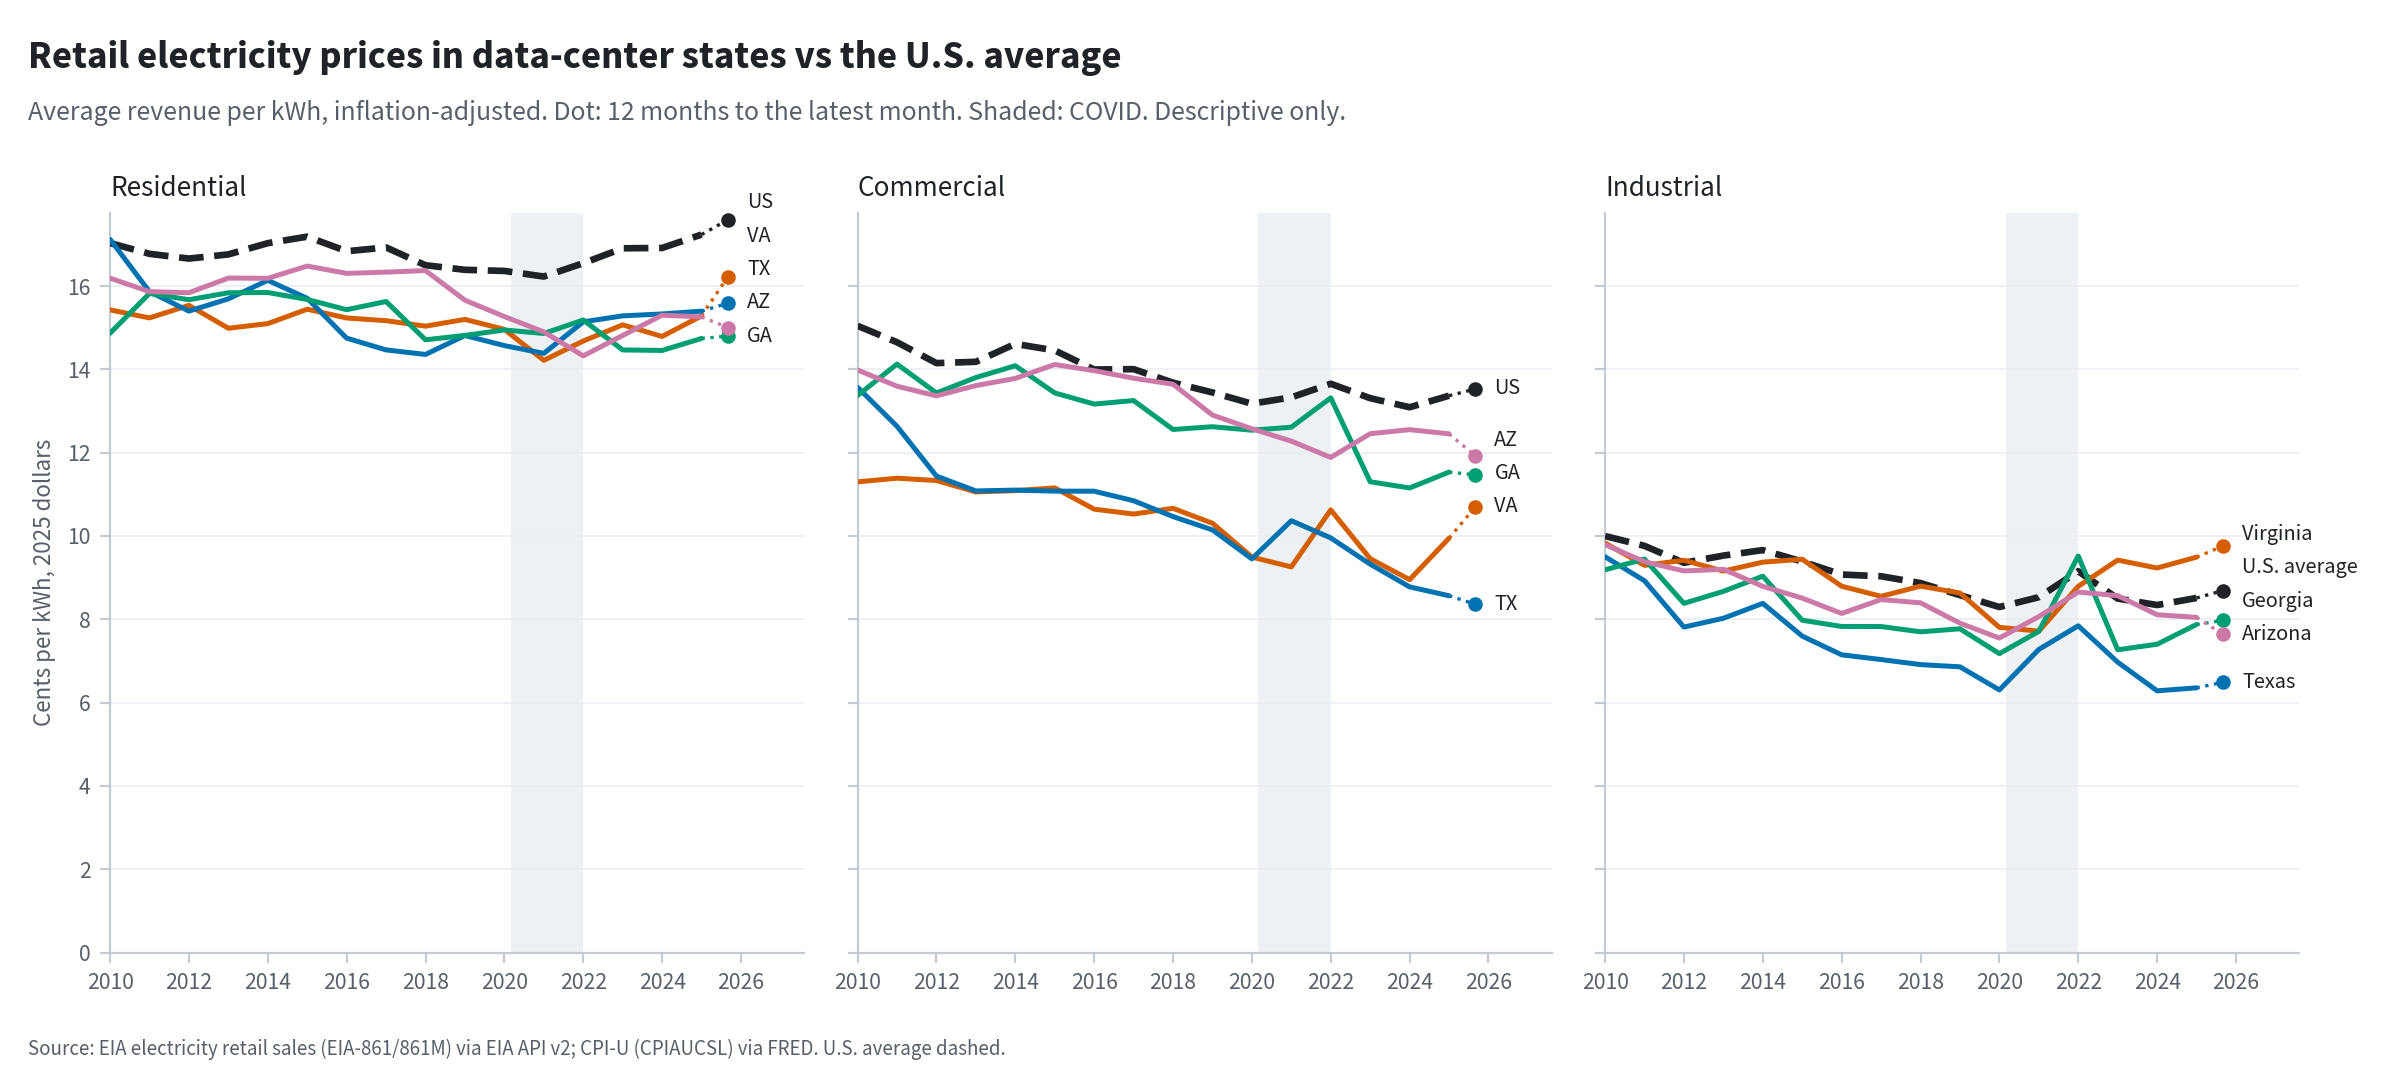

In [6]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['retail_prices'])
Image(filename=str(F.FIGURES_DIR / 'retail_prices.png'), width=900)

In [7]:
real = [c for c in retail.columns if c.startswith('price_real_')][0]
retail.filter(pl.col('sector').is_in(['RES', 'COM', 'ALL']) & pl.col('state').is_in(['US', 'VA', 'TX', 'GA', 'AZ', 'OR', 'WA'])
             & (pl.col('year').is_in([2019, 2021, 2025]) | pl.col('trailing'))).select('state', 'sector', 'period', 'price_cents_kwh', real).sort(
    'sector', 'state', 'period').with_columns(pl.col(pl.Float64).round(2))

state,sector,period,price_cents_kwh,price_real_2025
str,str,str,f64,f64
"""AZ""","""ALL""","""12 months to 2026-08""",12.85,12.53
"""AZ""","""ALL""","""2019""",10.52,13.25
"""AZ""","""ALL""","""2021""",10.73,12.74
"""AZ""","""ALL""","""2025""",12.95,12.95
"""GA""","""ALL""","""12 months to 2026-08""",12.38,12.08
"""GA""","""ALL""","""2019""",9.86,12.42
"""GA""","""ALL""","""2021""",10.43,12.4
"""GA""","""ALL""","""2025""",12.06,12.06
"""OR""","""ALL""","""12 months to 2026-08""",11.44,11.16
